# 02 · Sentiment: what the text says vs what players voted

Every Steam review has a thumbs up or down (`recommended`). This notebook asks:

1. Can a standard sentiment tool (VADER) recover that vote from the text alone?
2. Where do text and vote disagree, and why?
3. Which words separate positive from negative reviews in each game?
4. Does text sentiment move over time the same way the thumbs do?

**Input:** `data/processed/reviews_clean.csv` (from notebook 01)  
**Output:** `data/processed/reviews_scored.csv` and charts in `images/`

In [34]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, confusion_matrix
from sklearn.model_selection import train_test_split

PROC = Path("../data/processed")
IMG = Path("../images")
IMG.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 160)

df_all = pd.read_csv(PROC / "reviews_clean.csv", parse_dates=["month"])

# Text analysis only makes sense for reviews with 3+ words ("10/10" or "fun" carry no text signal).
# Vote-based numbers (% thumbs up over time) still use every review via df_all.
df = df_all[~df_all["is_short"]].copy()
print(f"{len(df_all):,} reviews in total, {len(df):,} with 3+ words used for text analysis, "
      f"{df['game'].nunique()} games")

306,571 reviews in total, 246,362 with 3+ words used for text analysis, 5 games


## 1. VADER sentiment score

VADER is a rule-based sentiment tool. `compound` runs from -1 (very negative) to +1 (very positive). It is fast and needs no training, so it is a good baseline, but it does not understand gaming slang or sarcasm.

In [35]:
analyzer = SentimentIntensityAnalyzer()
df["vader"] = df["review"].map(lambda t: analyzer.polarity_scores(t)["compound"])

def to_label(x):
    if x >= 0.05:
        return "positive"
    if x <= -0.05:
        return "negative"
    return "neutral"

df["vader_label"] = df["vader"].map(to_label)
df["vader_label"].value_counts(normalize=True).round(3)

vader_label
positive    0.750
negative    0.149
neutral     0.101
Name: proportion, dtype: float64

## 2. How well does VADER match the thumbs up/down?

In [36]:
scored = df[df["vader_label"] != "neutral"].copy()
scored["vader_pred"] = (scored["vader_label"] == "positive").astype(int)

overall = pd.Series({
    "accuracy": accuracy_score(scored["recommended"], scored["vader_pred"]),
    "f1": f1_score(scored["recommended"], scored["vader_pred"]),
    "roc_auc (using the raw score)": roc_auc_score(scored["recommended"], scored["vader"]),
    "baseline accuracy (always guess 'positive')": scored["recommended"].mean(),
    "share of reviews VADER calls neutral": (df["vader_label"] == "neutral").mean(),
}).round(3)
overall

accuracy                                       0.859
f1                                             0.917
roc_auc (using the raw score)                  0.804
baseline accuracy (always guess 'positive')    0.855
share of reviews VADER calls neutral           0.101
dtype: float64

In [37]:
by_game = (scored.groupby("game")
    .apply(lambda g: pd.Series({
        "reviews": len(g),
        "baseline_acc": g["recommended"].mean(),
        "accuracy": accuracy_score(g["recommended"], g["vader_pred"]),
        "auc": roc_auc_score(g["recommended"], g["vader"]) if g["recommended"].nunique() > 1 else np.nan,
    }), include_groups=False)
    .round(3))
by_game

,reviews,baseline_acc,accuracy,auc
game,,,,
Battlefield 2042,28125.0,0.516,0.737,0.784
Cyberpunk 2077,39069.0,0.897,0.861,0.771
Helldivers 2,17846.0,0.735,0.754,0.731
No Man's Sky,66332.0,0.871,0.869,0.771
Stardew Valley,70038.0,0.985,0.924,0.785


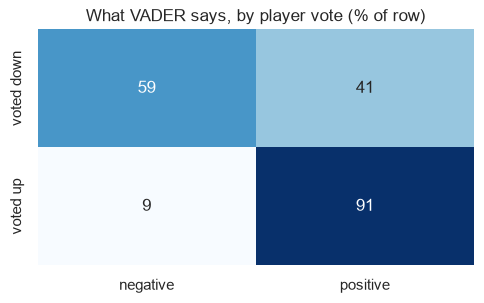

In [38]:
cm = pd.crosstab(scored["recommended"].map({1: "voted up", 0: "voted down"}),
                 scored["vader_label"], normalize="index") * 100

fig, ax = plt.subplots(figsize=(5, 3.2))
sns.heatmap(cm, annot=True, fmt=".0f", cmap="Blues", cbar=False, ax=ax)
ax.set(title="What VADER says, by player vote (% of row)", xlabel="", ylabel="")
fig.tight_layout()
fig.savefig(IMG / "vader_vs_vote.png", dpi=150)
plt.show()

**Read AUC, not accuracy.** Most reviews are thumbs up, so a tool that always says "positive" already scores the `baseline_acc` above. AUC measures how well the score *ranks* positive reviews above negative ones and is not inflated by that imbalance.

## 3. Where text and vote disagree

These are the interesting cases: a thumbs up with very negative wording, or a thumbs down with very positive wording. Read them before trusting any sentiment number.

In [39]:
up_but_negative = (df[(df["recommended"] == 1) & (df["vader"] <= -0.6)]
                   .sample(8, random_state=1, replace=False) if ((df["recommended"] == 1) & (df["vader"] <= -0.6)).sum() >= 8
                   else df[(df["recommended"] == 1) & (df["vader"] <= -0.6)])
up_but_negative[["game", "vader", "review"]]

,game,vader,review
150434,No Man's Sky,-0.7354,"Not perfect, but will provide hours of entertainment. Even though it had a rocky start, the devs never gave up, and they keep improving upon their game. The..."
111227,Helldivers 2,-0.9136,HELL YEAH KILL SHIT
248910,Stardew Valley,-0.7665,very bad game very hard to play with people wtf
101205,Helldivers 2,-0.8338,now my previous review was negative but that was years ago and my playtime has increased drastically and things have in fact changed you will hear alot abou...
155058,No Man's Sky,-0.9716,"Best if you really enjoy exploration and base building. You can get into as much PVE scrapping as you like, but it's GTA style. If you destroy the PVE enemy..."
50067,Cyberpunk 2077,-0.8625,"Game was obviously a little buggy but they fixed most of the major ones. Story felt super short even when I was doing side quests, but the characters felt r..."
39861,Cyberpunk 2077,-0.9728,"The game in its core.. Well, it's there. If you can take the constant visual bugs, gameplay bugs, and a handful of game breaking bugs, then go for it. This ..."
115429,Helldivers 2,-0.6908,"You kill bugs, robots, and aliens.\r\n\r\nWhat more could you ask for?"


In [40]:
down_but_positive = df[(df["recommended"] == 0) & (df["vader"] >= 0.6)]
down_but_positive = down_but_positive.sample(min(8, len(down_but_positive)), random_state=1)
down_but_positive[["game", "vader", "review"]]

,game,vader,review
5350,Battlefield 2042,0.9589,I bought this game and was very excited to play it. The first 10 hours of playing the game were very fun with friends but still lacked a lot of good content...
2992,Battlefield 2042,0.7156,Was a great comeback then they required secure boot and a lot more bio surgery to play the game. Worst decision they could have made. Instantly locked thous...
158316,No Man's Sky,0.7285,On the PS4 version the game was not deep or complex and in the past it had a simple beauty to it all (till the updates). This was one of those chilled exper...
112295,Helldivers 2,0.7927,"It's a great game, probably the best power fantasy horde shooter I've ever played. \n\nUnfortunately, the developers didn't mean to make that, so have been ..."
11961,Battlefield 2042,0.7733,"I have been a battlefield vet since Bad company, the original and best battlefield. Ill have to say, this last few updates took a pretty well running game ..."
113157,Helldivers 2,0.8610,After seeing a lot of people really enjoing this game i tought to myself that it must be very good but honestly it was a mistake. On lower difs the game is ...
148539,No Man's Sky,0.8720,Honestly it crashed about once every 2 hours. that about the average crashed ive had while playing other than that its pretty good
146287,No Man's Sky,0.7616,"This game frustrates me so much and I just started playing. I lost my ship in the beginning of the game, I had no way to retrieve it, I died and it didn't s..."


**What to look for:** thumbs-up reviews that sound negative are often describing dark themes, bugs they put up with, or sarcasm ("this game ruined my sleep schedule, 10/10"). Thumbs-down reviews that sound positive are often "I love the idea, but it is broken". This is the main reason to use the player vote as ground truth and the text for the *why*.

## 4. Supervised baseline: predict the vote from the words

In [41]:
X_train, X_test, y_train, y_test = train_test_split(
    df["review"], df["recommended"], test_size=0.2, random_state=42, stratify=df["recommended"])

tfidf = TfidfVectorizer(min_df=5, ngram_range=(1, 2), stop_words="english", sublinear_tf=True, max_features=50000)
Xtr = tfidf.fit_transform(X_train)
Xte = tfidf.transform(X_test)

clf = LogisticRegression(max_iter=1000, class_weight="balanced")
clf.fit(Xtr, y_train)
proba = clf.predict_proba(Xte)[:, 1]
pred = (proba >= 0.5).astype(int)

pd.Series({
    "accuracy": accuracy_score(y_test, pred),
    "f1": f1_score(y_test, pred),
    "roc_auc": roc_auc_score(y_test, proba),
}).round(3)

accuracy    0.908
f1          0.944
roc_auc     0.959
dtype: float64

A model trained on the actual votes should beat VADER, because it learns the words that matter in *this* domain (for example, "refund" or "crash"). If it does not, the text may carry little signal beyond what VADER already finds.

### Words that push a review toward thumbs up or down (all games)

In [42]:
terms = np.array(tfidf.get_feature_names_out())
coef = clf.coef_[0]
top_pos = pd.DataFrame({"word": terms[np.argsort(coef)[-15:][::-1]], "weight": np.sort(coef)[-15:][::-1].round(2)})
top_neg = pd.DataFrame({"word": terms[np.argsort(coef)[:15]], "weight": np.sort(coef)[:15].round(2)})
pd.concat([top_pos.add_prefix("up_"), top_neg.add_prefix("down_")], axis=1)

,up_word,up_weight,down_word,down_weight
0,amazing,9.02,refund,-8.66
1,10 10,8.92,boring,-8.33
2,love,8.32,arrowhead,-7.65
3,best,7.49,worst,-7.49
4,relaxing,7.29,ea,-6.90
5,addicting,6.75,garbage,-6.78
6,great,6.45,unplayable,-6.70
7,masterpiece,6.18,worse,-6.57
8,perfect,5.85,terrible,-6.31
9,farm,5.66,crashes,-5.78


### Distinctive words per game

In [43]:
rows = []
for game, g in df.groupby("game"):
    if g["recommended"].nunique() < 2 or len(g) < 200:
        continue
    vec = TfidfVectorizer(min_df=5, ngram_range=(1, 2), stop_words="english", sublinear_tf=True, max_features=20000)
    Xg = vec.fit_transform(g["review"])
    m = LogisticRegression(max_iter=1000, class_weight="balanced").fit(Xg, g["recommended"])
    t = np.array(vec.get_feature_names_out()); c = m.coef_[0]
    rows.append({"game": game,
                 "positive words": ", ".join(t[np.argsort(c)[-8:][::-1]]),
                 "negative words": ", ".join(t[np.argsort(c)[:8]])})
pd.DataFrame(rows)

,game,positive words,negative words
0,Battlefield 2042,"fun, good, great, best, love, sale, amazing, solid","garbage, worst, ea, money, refund, waste, tried, unplayable"
1,Cyberpunk 2077,"amazing, masterpiece, best, great, favorite, 10 10, perfect, love","boring, crashes, terrible, refund, disappointment, crashing, repetitive, unplayable"
2,Helldivers 2,"democracy, best, great, fun, 10 10, love, good, amazing","devs, arrowhead, worse, fix, developers, anymore, unplayable, update"
3,No Man's Sky,"love, amazing, 10 10, great, awesome, relaxing, best, great game","boring, refund, unplayable, worst, tried, terrible, worse, crashes"
4,Stardew Valley,"10 10, best, amazing, love game, relaxing, perfect, addicting, great game","boring, refund, awful, good great, gba, expected, tedious, slow"


## 5. Sentiment over time: text vs thumbs

In [44]:
# Sanity check: how many reviews sit behind the most recent months?
(df_all.groupby(["game", "month"]).size().rename("n").reset_index()
   .sort_values("month").groupby("game").tail(3).sort_values(["game", "month"]))

,game,month,n
57,Battlefield 2042,2026-08-01,166
58,Battlefield 2042,2026-09-01,122
59,Battlefield 2042,2026-10-01,99
128,Cyberpunk 2077,2026-08-01,797
129,Cyberpunk 2077,2026-09-01,791
130,Cyberpunk 2077,2026-10-01,795
161,Helldivers 2,2026-08-01,794
162,Helldivers 2,2026-09-01,793
163,Helldivers 2,2026-10-01,797
284,No Man's Sky,2026-08-01,795


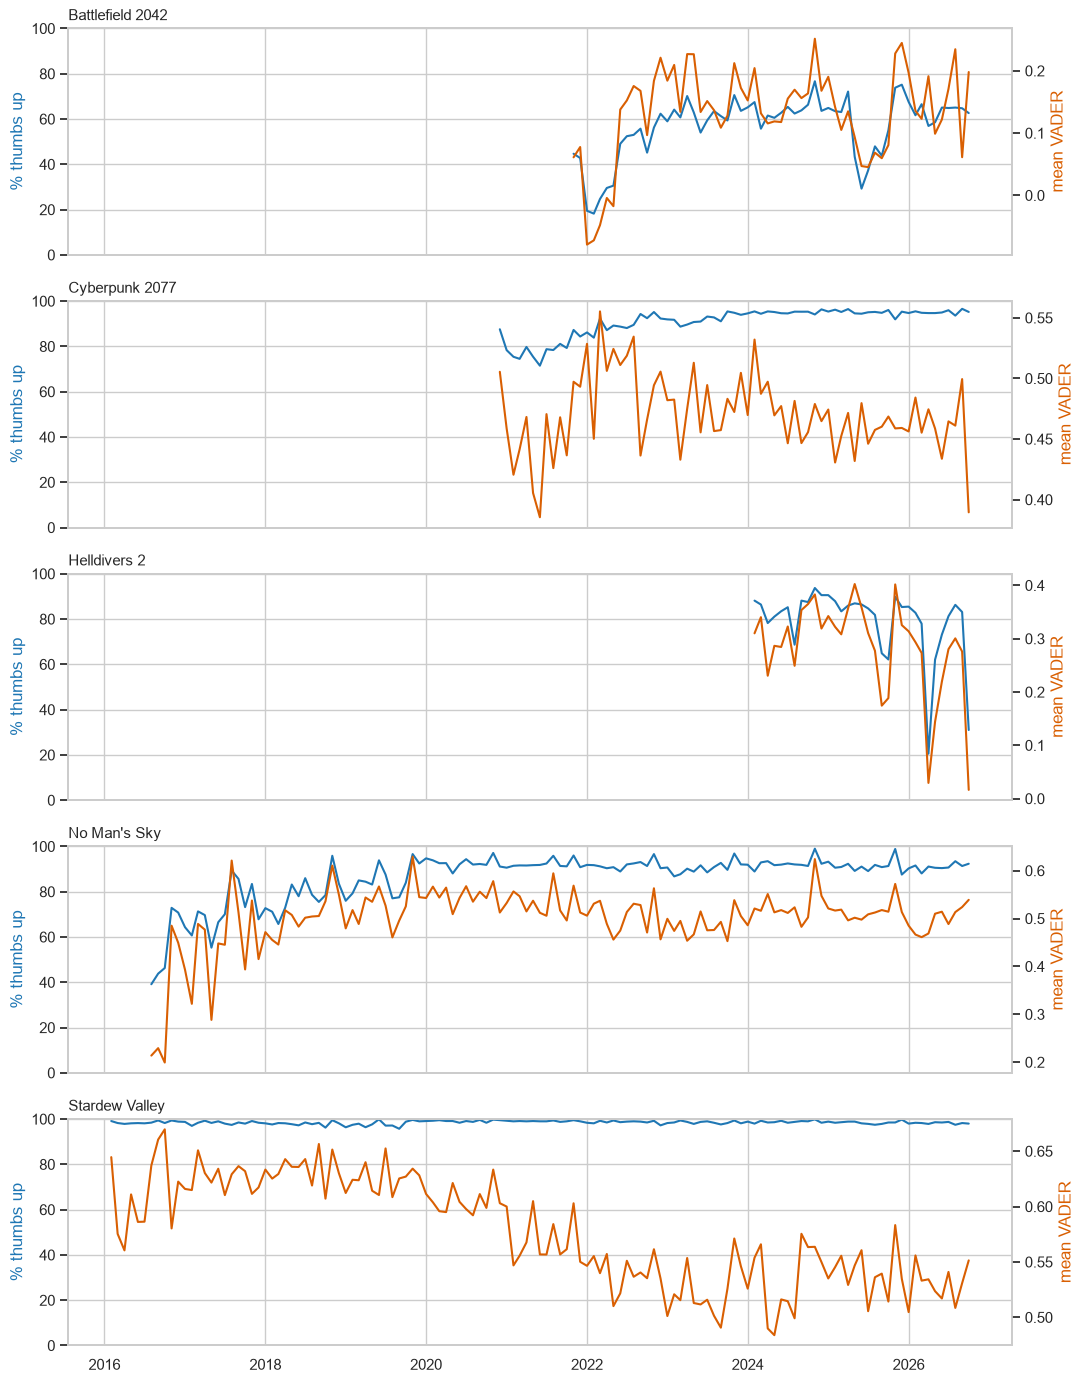

In [45]:
MIN_N = 30
votes = (df_all.groupby(["game", "month"])
                .agg(pct_positive=("recommended", "mean"), n=("recommended", "size")))
text = df.groupby(["game", "month"]).agg(vader=("vader", "mean"))
m = votes.join(text).reset_index()
if (m["n"] >= MIN_N).any():
    m = m[m["n"] >= MIN_N]
else:
    print(f"No month has {MIN_N}+ reviews, showing all months (values will be noisy)")
m["pct_positive"] *= 100

games = m["game"].unique()
fig, axes = plt.subplots(len(games), 1, figsize=(11, 2.8 * len(games)), sharex=True)
axes = np.atleast_1d(axes)
for ax, game in zip(axes, games):
    g = m[m["game"] == game]
    ax.plot(g["month"], g["pct_positive"], color="#1f77b4", label="% thumbs up")
    ax.set_ylabel("% thumbs up", color="#1f77b4"); ax.set_ylim(0, 100)
    ax2 = ax.twinx()
    ax2.plot(g["month"], g["vader"], color="#d95f02", label="mean VADER")
    ax2.set_ylabel("mean VADER", color="#d95f02"); ax2.grid(False)
    ax.set_title(game, loc="left", fontsize=11)
fig.tight_layout()
fig.savefig(IMG / "sentiment_over_time.png", dpi=150)
plt.show()

### Does review length change over time?

Stardew Valley stays about 98% thumbs up, but its text sentiment drifts down. One explanation is that reviews get shorter and more casual. This checks it.

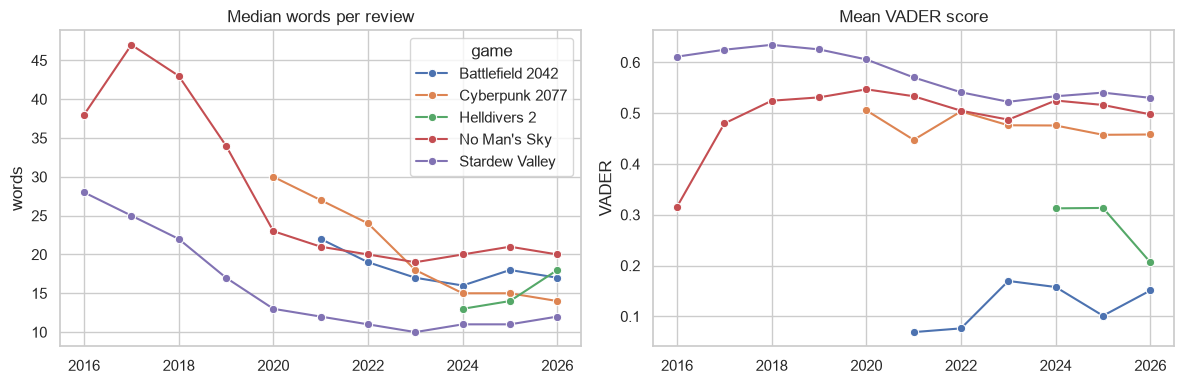

In [46]:
yr = (df.groupby(["game", "year"] if "year" in df.columns else ["game", df["month"].dt.year.rename("year")])
        .agg(median_words=("word_count", "median"), mean_vader=("vader", "mean"), n=("vader", "size"))
        .reset_index())
yr = yr[yr["n"] >= 100]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.lineplot(data=yr, x="year", y="median_words", hue="game", marker="o", ax=axes[0])
axes[0].set(title="Median words per review", xlabel="", ylabel="words")
sns.lineplot(data=yr, x="year", y="mean_vader", hue="game", marker="o", ax=axes[1], legend=False)
axes[1].set(title="Mean VADER score", xlabel="", ylabel="VADER")
fig.tight_layout()
fig.savefig(IMG / "length_and_sentiment_by_year.png", dpi=150)
plt.show()

## 6. Optional: a transformer model

A pretrained transformer usually handles sarcasm and slang better than VADER. It is slow on CPU, so it runs on a **sample** and is switched off by default. Set `USE_TRANSFORMER = True` and install `transformers` and `torch` first.

In [47]:
USE_TRANSFORMER = False
SAMPLE = 3000

if USE_TRANSFORMER:
    from transformers import pipeline
    clf_tf = pipeline("sentiment-analysis", model="cardiffnlp/twitter-roberta-base-sentiment-latest",
                      truncation=True, max_length=256)
    s = df.sample(min(SAMPLE, len(df)), random_state=1).copy()
    out = clf_tf(s["review"].tolist(), batch_size=32)
    s["tf_label"] = [o["label"].lower() for o in out]
    s = s[s["tf_label"] != "neutral"]
    s["tf_pred"] = (s["tf_label"] == "positive").astype(int)
    print("transformer accuracy:", round(accuracy_score(s["recommended"], s["tf_pred"]), 3))
    s2 = s.copy(); s2["vader_pred"] = (s2["vader"] >= 0.05).astype(int)
    print("VADER accuracy on same sample:", round(accuracy_score(s2["recommended"], s2["vader_pred"]), 3))
else:
    print("Transformer step skipped (USE_TRANSFORMER = False)")

Transformer step skipped (USE_TRANSFORMER = False)


## 7. Save

In [48]:
keep = ["recommendationid", "game", "month", "recommended", "playtime_hours", "playtime_bucket",
        "word_count", "vader", "vader_label", "review"]
df[keep].to_csv(PROC / "reviews_scored.csv", index=False)
print(f"saved {len(df):,} scored reviews")

saved 246,362 scored reviews


## Notes for the README

- VADER is a rule-based baseline. It misreads sarcasm, slang and gameplay words like "kill", "dark" or "grind", so the player's vote is treated as ground truth.
- The TF-IDF model is trained on a random 80/20 split of the sampled reviews, so its scores describe this dataset and not Steam in general.
- Reviews are dated by when they were first posted.